# End-to-End Credit Risk Predictive Modeling


### Download dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ayushsharma0812/dataset-for-credit-score-classification")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\voila\.cache\kagglehub\datasets\ayushsharma0812\dataset-for-credit-score-classification\versions\1


### Load essential libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### Load datasets

In [3]:
file_path = "D:\\Tools\\Credit-risk-predictive-modeling\\Dataset\\Credit_score_cleaned_data.csv"
df = pd.read_csv(file_path)
df.columns = df.columns.str.lower()

### EDA the datasets

In [4]:
# Set options to display full columns
pd.set_option('display.max_columns', None)
print("==="*10,"First 5 rows","==="*10)
display(df.head(5))
print("==="*10,"Dataset Overview","==="*10)
df.info()
print("==="*10,"Descriptive Statistics of the dataset","==="*10)
display(df.describe())

============================== First 5 rows ==============================


,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,payment_behaviour,monthly_balance,last_loan_9,last_loan_8,last_loan_7,last_loan_6,last_loan_5,last_loan_4,last_loan_3,last_loan_2,last_loan_1,credit_score
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,10,9.44,9,Standard,1396.14,33.061861,156,Yes,52.138474,44.084010,High_spent_Medium_value_payments,321.019683,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Debt Consolidation Loan,Standard
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,8,9.64,2,Standard,268.81,36.377621,269,Yes,51.934634,39.628311,Low_spent_Small_value_payments,327.009597,No Loan,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Auto Loan,Auto Loan,Standard
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,12,8.51,0,Good,180.70,39.917508,326,No,0.000000,84.774645,High_spent_Small_value_payments,432.727105,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Good
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,17,17.51,3,Standard,569.11,39.841494,376,Yes,16.941903,41.943603,Low_spent_Medium_value_payments,346.630494,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Personal Loan,Student Loan,Home Equity Loan,Standard
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,20,17.16,6,Bad,3003.45,36.058472,162,Yes,126.596814,67.970377,High_spent_Medium_value_payments,360.325808,No Loan,No Loan,No Loan,No Loan,Auto Loan,Mortgage Loan,Auto Loan,Payday Loan,Not Specified,Poor


============================== Dataset Overview ==============================
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 32 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   customer_id               100000 non-null  str    
 1   age                       100000 non-null  int64  
 2   occupation                100000 non-null  str    
 3   annual_income             100000 non-null  float64
 4   monthly_inhand_salary     100000 non-null  float64
 5   num_bank_accounts         100000 non-null  int64  
 6   num_credit_card           100000 non-null  int64  
 7   interest_rate             100000 non-null  float64
 8   num_of_loan               100000 non-null  int64  
 9   delay_from_due_date       100000 non-null  int64  
 10  num_of_delayed_payment    100000 non-null  int64  
 11  changed_credit_limit      100000 non-null  float64
 12  num_credit_inquiries      100000 

,age,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,outstanding_debt,credit_utilization_ratio,credit_history_age,total_emi_per_month,amount_invested_monthly,monthly_balance
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,33.309240,50505.123449,4198.771859,5.368800,5.533640,14.53208,3.532880,21.068780,13.329240,10.389098,5.772820,1426.220376,32.285173,221.206880,88.209450,193.686347,403.492393
std,10.764996,38299.422093,3187.494345,2.593279,2.067073,8.74133,2.446356,14.860104,6.269066,6.783550,3.861137,1155.129026,5.116875,99.681112,83.244703,194.785222,214.423009
min,14.000000,7005.930000,303.645417,0.000000,0.000000,1.00000,0.000000,-5.000000,0.000000,-6.490000,0.000000,0.230000,20.000000,1.000000,-1.000000,0.000000,0.007760
25%,24.000000,19342.972500,1626.761667,3.000000,4.000000,7.00000,2.000000,10.000000,9.000000,5.340000,3.000000,566.072500,28.052567,144.000000,25.589532,73.730625,270.322511
50%,33.000000,36999.705000,3096.378333,5.000000,5.000000,13.00000,3.000000,18.000000,14.000000,9.400000,5.000000,1166.155000,32.305784,219.000000,61.541296,129.361839,337.270985
75%,42.000000,71683.470000,5961.745000,7.000000,7.000000,20.00000,5.000000,28.000000,18.000000,14.850000,8.000000,1945.962500,36.496663,302.000000,131.528154,234.346249,471.928804
max,56.000000,179987.280000,15204.633333,11.000000,11.000000,34.00000,9.000000,67.000000,28.000000,36.970000,17.000000,4998.070000,50.000000,404.000000,357.406068,1977.326102,1602.040519


In [5]:
print(df.columns)

Index(['customer_id', 'age', 'occupation', 'annual_income',
       'monthly_inhand_salary', 'num_bank_accounts', 'num_credit_card',
       'interest_rate', 'num_of_loan', 'delay_from_due_date',
       'num_of_delayed_payment', 'changed_credit_limit',
       'num_credit_inquiries', 'credit_mix', 'outstanding_debt',
       'credit_utilization_ratio', 'credit_history_age',
       'payment_of_min_amount', 'total_emi_per_month',
       'amount_invested_monthly', 'payment_behaviour', 'monthly_balance',
       'last_loan_9', 'last_loan_8', 'last_loan_7', 'last_loan_6',
       'last_loan_5', 'last_loan_4', 'last_loan_3', 'last_loan_2',
       'last_loan_1', 'credit_score'],
      dtype='str')


#### Explore about qualitative variables

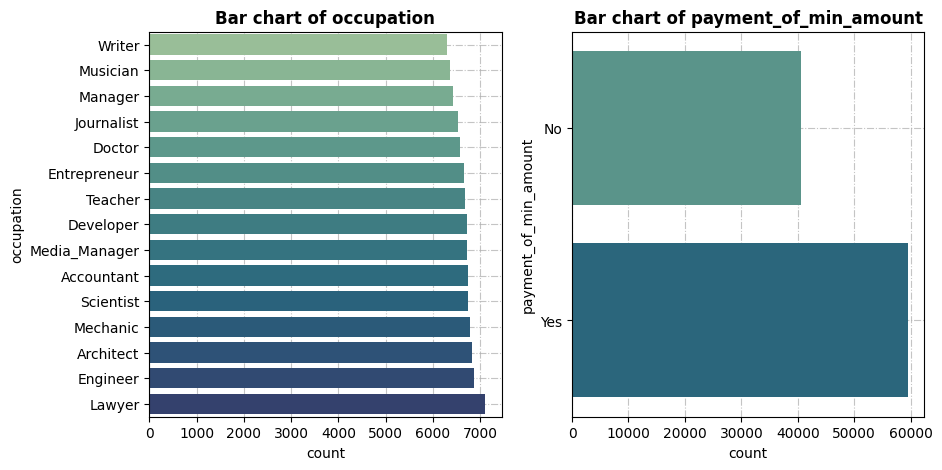

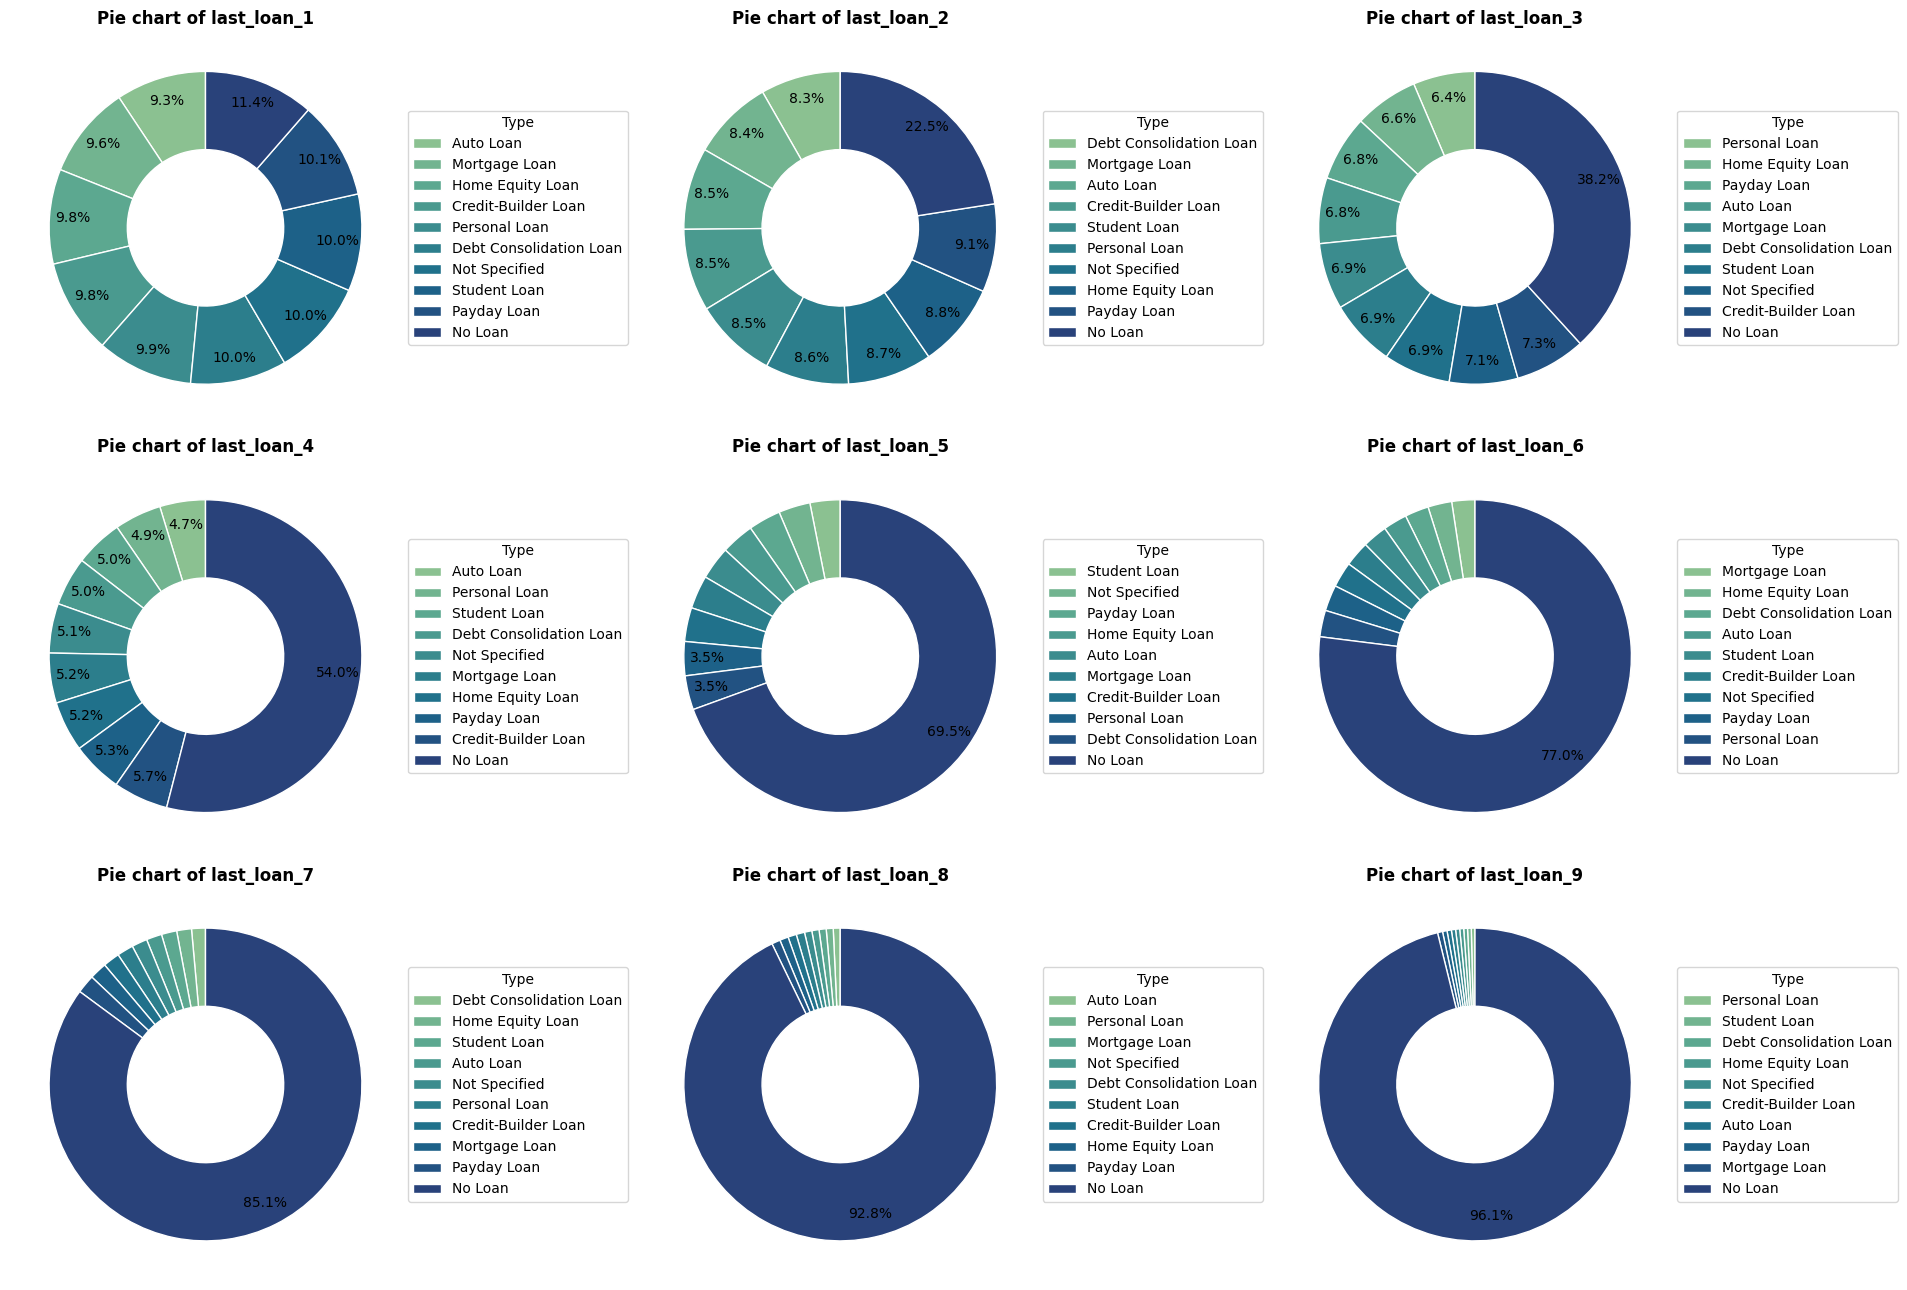

In [ ]:
# Draw bar chart for: 'occupation','payment_of_min_amount'
fig, axes = plt.subplots(1,2, figsize =(10,5))
other_col = ['occupation','payment_of_min_amount']


for ax, col in  zip(axes,other_col):
    other_col_count = df[col].value_counts().sort_values().reset_index()
    sns.barplot(data = other_col_count, y = col, x = 'count', ax = ax, hue = col, palette = 'crest')
    ax.grid(True, linestyle = '-.', alpha = 0.75)
    ax.set_axisbelow(True)
    ax.set_title(f'Bar chart of {col}', fontsize = 12, fontweight = 'bold', pad = 15)

# Draw donut charts for norminal scale variables
fig, axes = plt.subplots(3,3,figsize =(20,13))
last_loan = ['last_loan_1','last_loan_2','last_loan_3','last_loan_4','last_loan_5','last_loan_6','last_loan_7','last_loan_8','last_loan_9']
axes = axes.flatten()

for col, ax in zip(last_loan, axes):
    col_count = df[col].value_counts().sort_values(ascending = True).reset_index()
    colors = sns.color_palette('crest', n_colors = len(col_count))
    autopct = lambda pct: f'{pct:.1f}%' if pct > 3.5 else ''

# wedges: slices of the charts
    wedges, texts, autotexts = ax.pie(x = col_count['count'], labels = col_count[col], autopct =  autopct, startangle = 90,
                                  pctdistance=0.85, colors = colors,
                                  wedgeprops=dict(width=0.5, edgecolor='w'))
    for text in texts:
        text.set_text('')
    ax.legend(wedges, col_count[col], title="Type", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
    ax.set_title(f'Pie chart of {col}', fontsize = 12, fontweight = 'bold', pad = 15)


plt.tight_layout()
plt.show()

Value counts for column credit_score


,credit_score,count
0,Good,17828
1,Poor,28998
2,Standard,53174


Value counts for column credit_mix


,credit_mix,count
0,Bad,23768
1,Good,30384
2,Standard,45848


Value counts for column payment_behaviour


,payment_level,payment_volume,count
0,High payment,Large payment,15439
1,High payment,Medium payment,20812
2,High payment,Small payment,8253
3,Low payment,Large payment,7354
4,Low payment,Medium payment,11492
5,Low payment,Small payment,36650


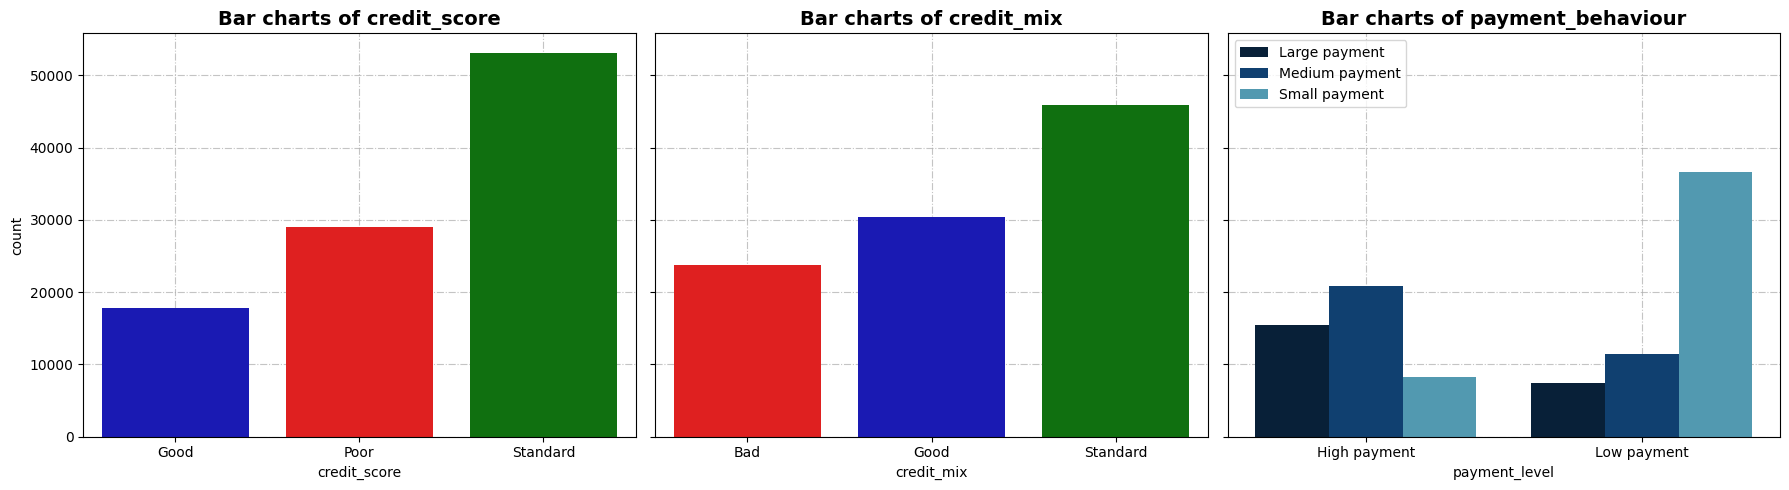

In [ ]:
# Add 2 more columns for payment_behaviour
df['payment_level'] = 'default'
df.loc[df['payment_behaviour'].str.contains('Low', case = False, na = False), 'payment_level'] = 'Low payment'
df.loc[df['payment_behaviour'].str.contains('High',case = False, na = False), 'payment_level'] = 'High payment'

df['payment_volume'] = 'default'
df.loc[df['payment_behaviour'].str.contains('Small', case = False, na = False), 'payment_volume'] = 'Small payment'
df.loc[df['payment_behaviour'].str.contains('Medium', case = False, na = False), 'payment_volume'] = 'Medium payment'
df.loc[df['payment_behaviour'].str.contains('Large', case = False, na = False), 'payment_volume'] = 'Large payment'

# Setup layout for ordinal variables
ordinal_cols = ['credit_score','credit_mix', 'payment_behaviour']
fig, axes = plt.subplots(1,3, figsize = (18,5), sharey = True)
color_score = {'Standard': 'green', 'Poor': 'red', 'Bad': 'red', 'Good': 'mediumblue'}
# Create bar charts
credit_score_count = df['credit_score'].value_counts().sort_values().reset_index()
sns.barplot(data = credit_score_count, y = 'count', x = 'credit_score', ax = axes[0], hue = 'credit_score', palette = color_score)

credit_mix_count = df['credit_mix'].value_counts().sort_values().reset_index()
sns.barplot(data = credit_mix_count, y = 'count', x = 'credit_mix', ax = axes[1], hue = 'credit_mix', palette = color_score)

df_payment_group = df.groupby(['payment_level','payment_volume']).size().reset_index(name = 'count')
sns.barplot(data = df_payment_group, x = 'payment_level', y = 'count', hue = 'payment_volume', ax = axes[2], palette = 'ocean')

# Set labels and display grouped tables for charts
ordinal_grouped_count_table = [credit_score_count, credit_mix_count, df_payment_group]

for ax, col, table in zip(axes,ordinal_cols, ordinal_grouped_count_table):
    ax.set_axisbelow(True)
    ax.grid(True, linestyle = '-.', alpha = 0.75)
    ax.set_title(f'Bar charts of {col}', fontsize = 14, fontweight = 'bold', pad = 15)
    print(f'Value counts for column {col}')
    display(table)

plt.legend(loc = 'upper left')
plt.tight_layout()
plt.show()

#### Explore about quantitative variables

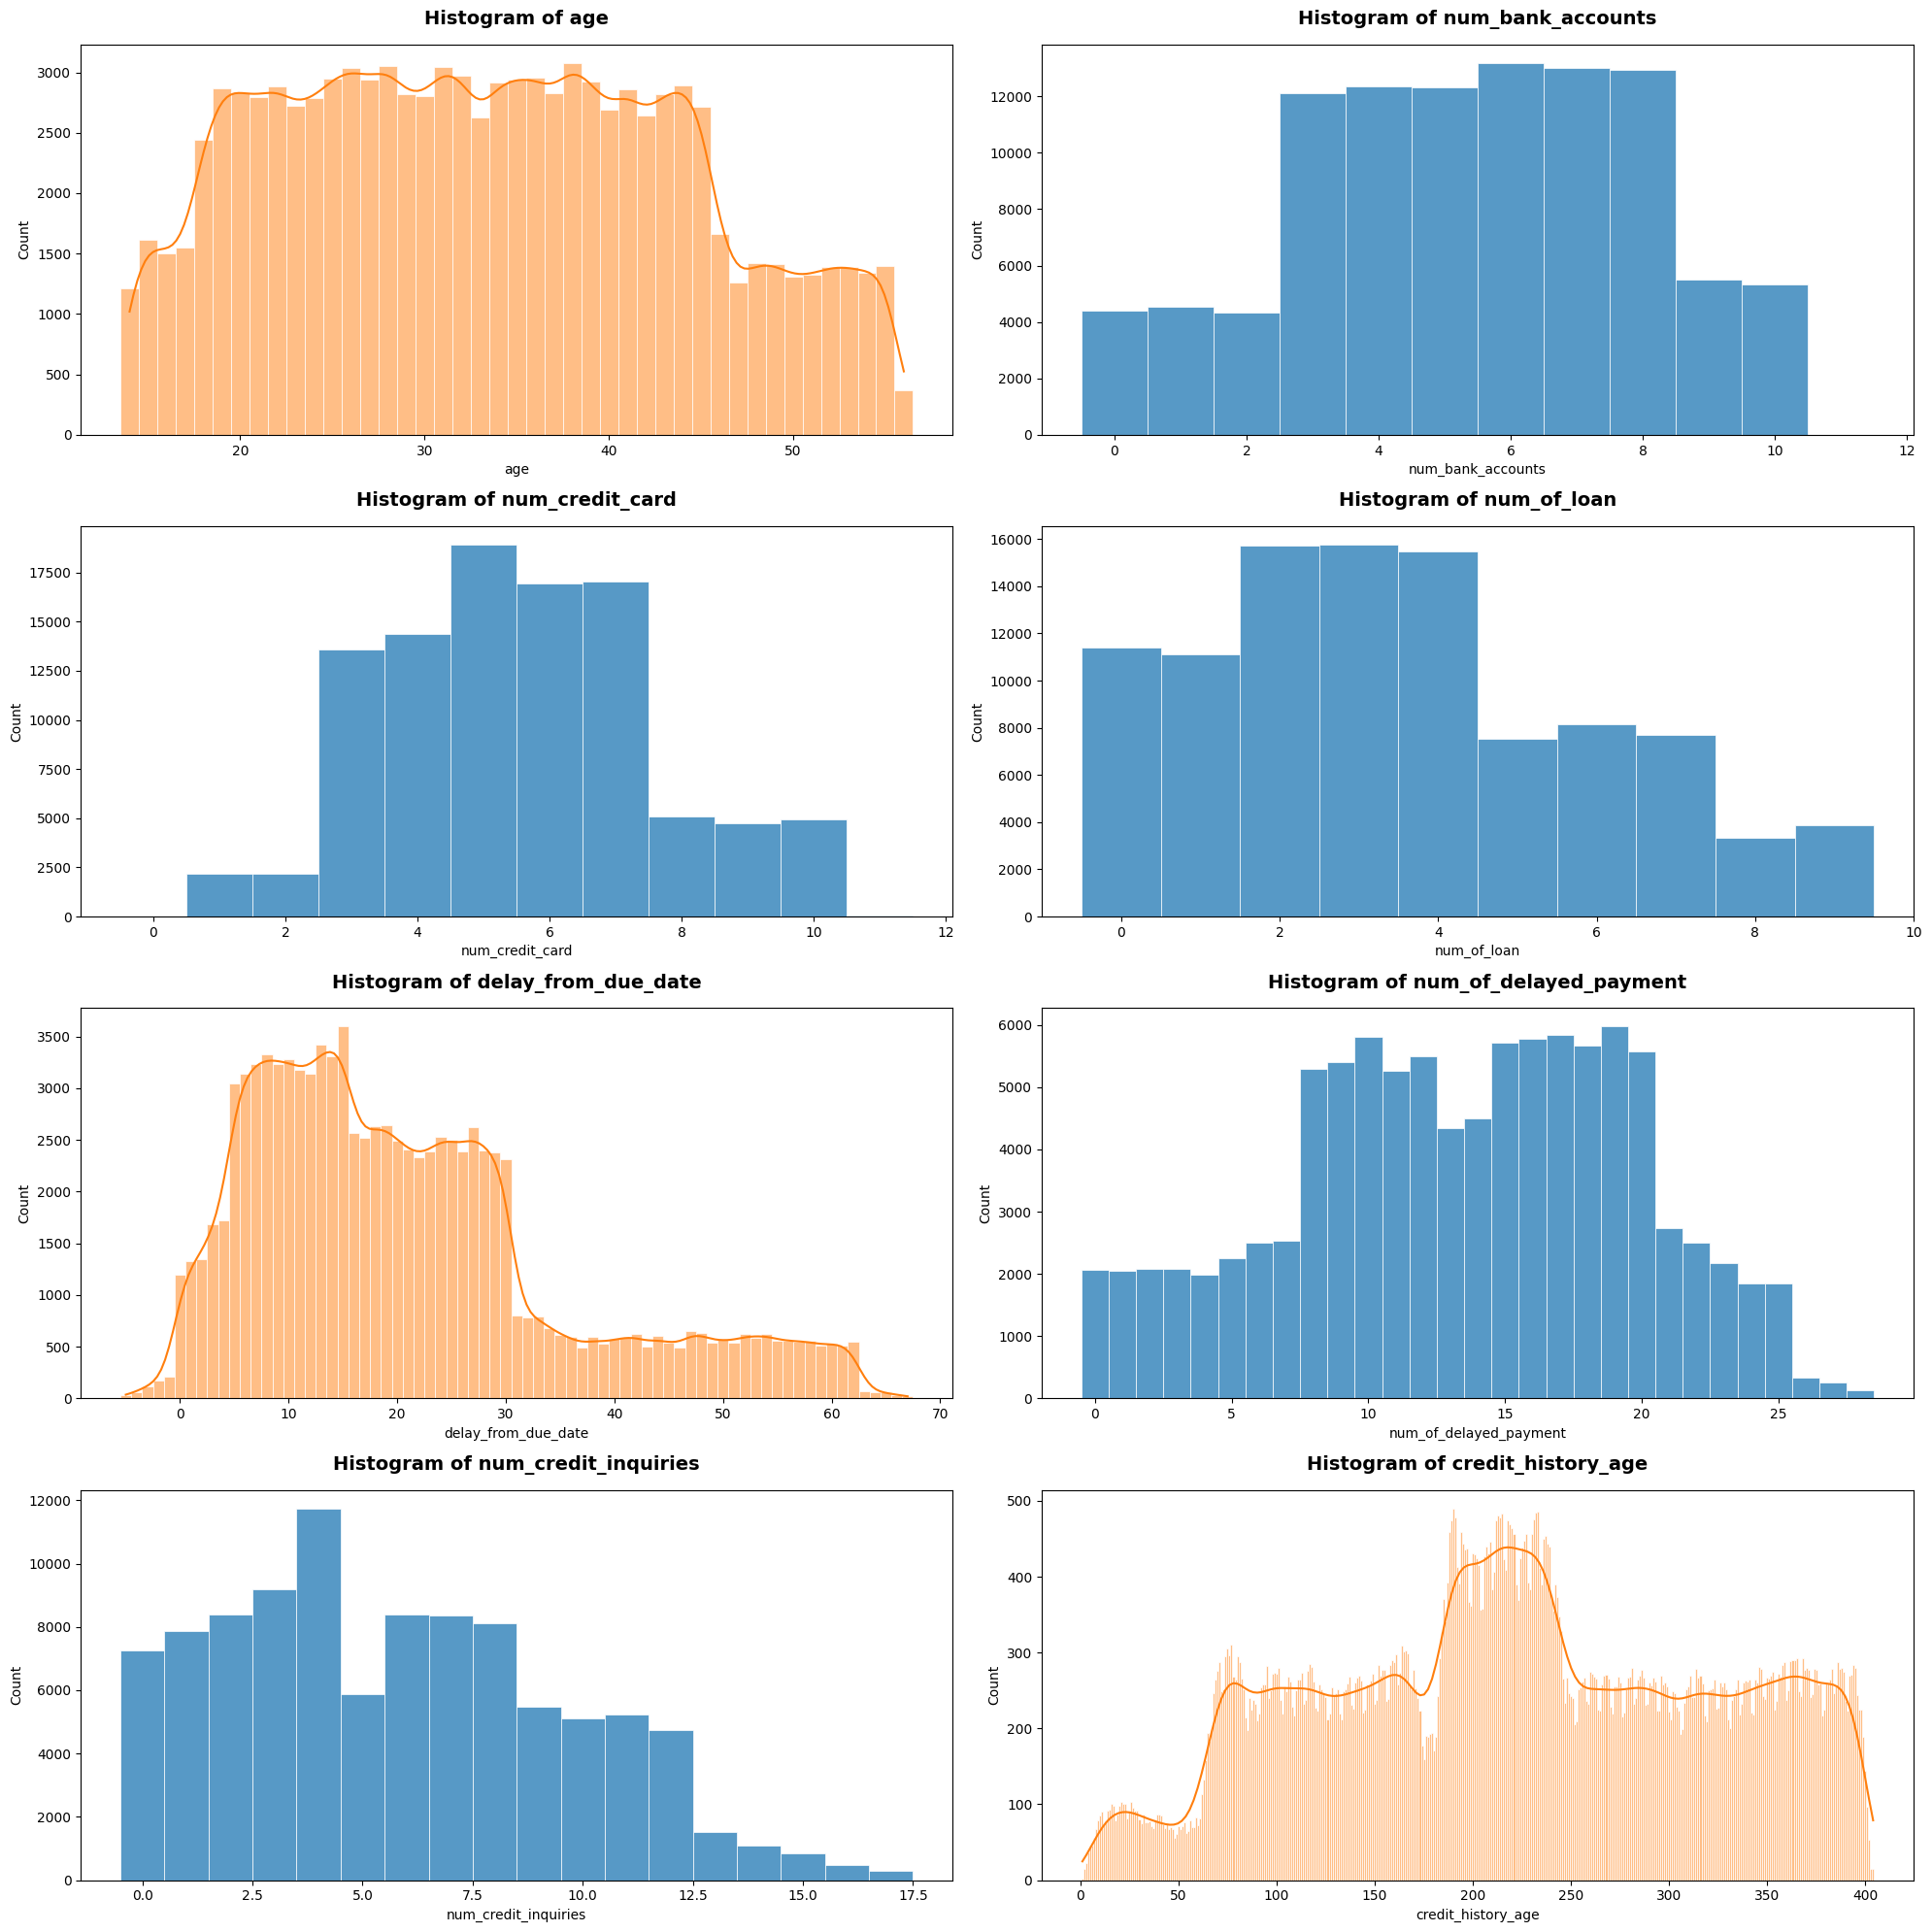

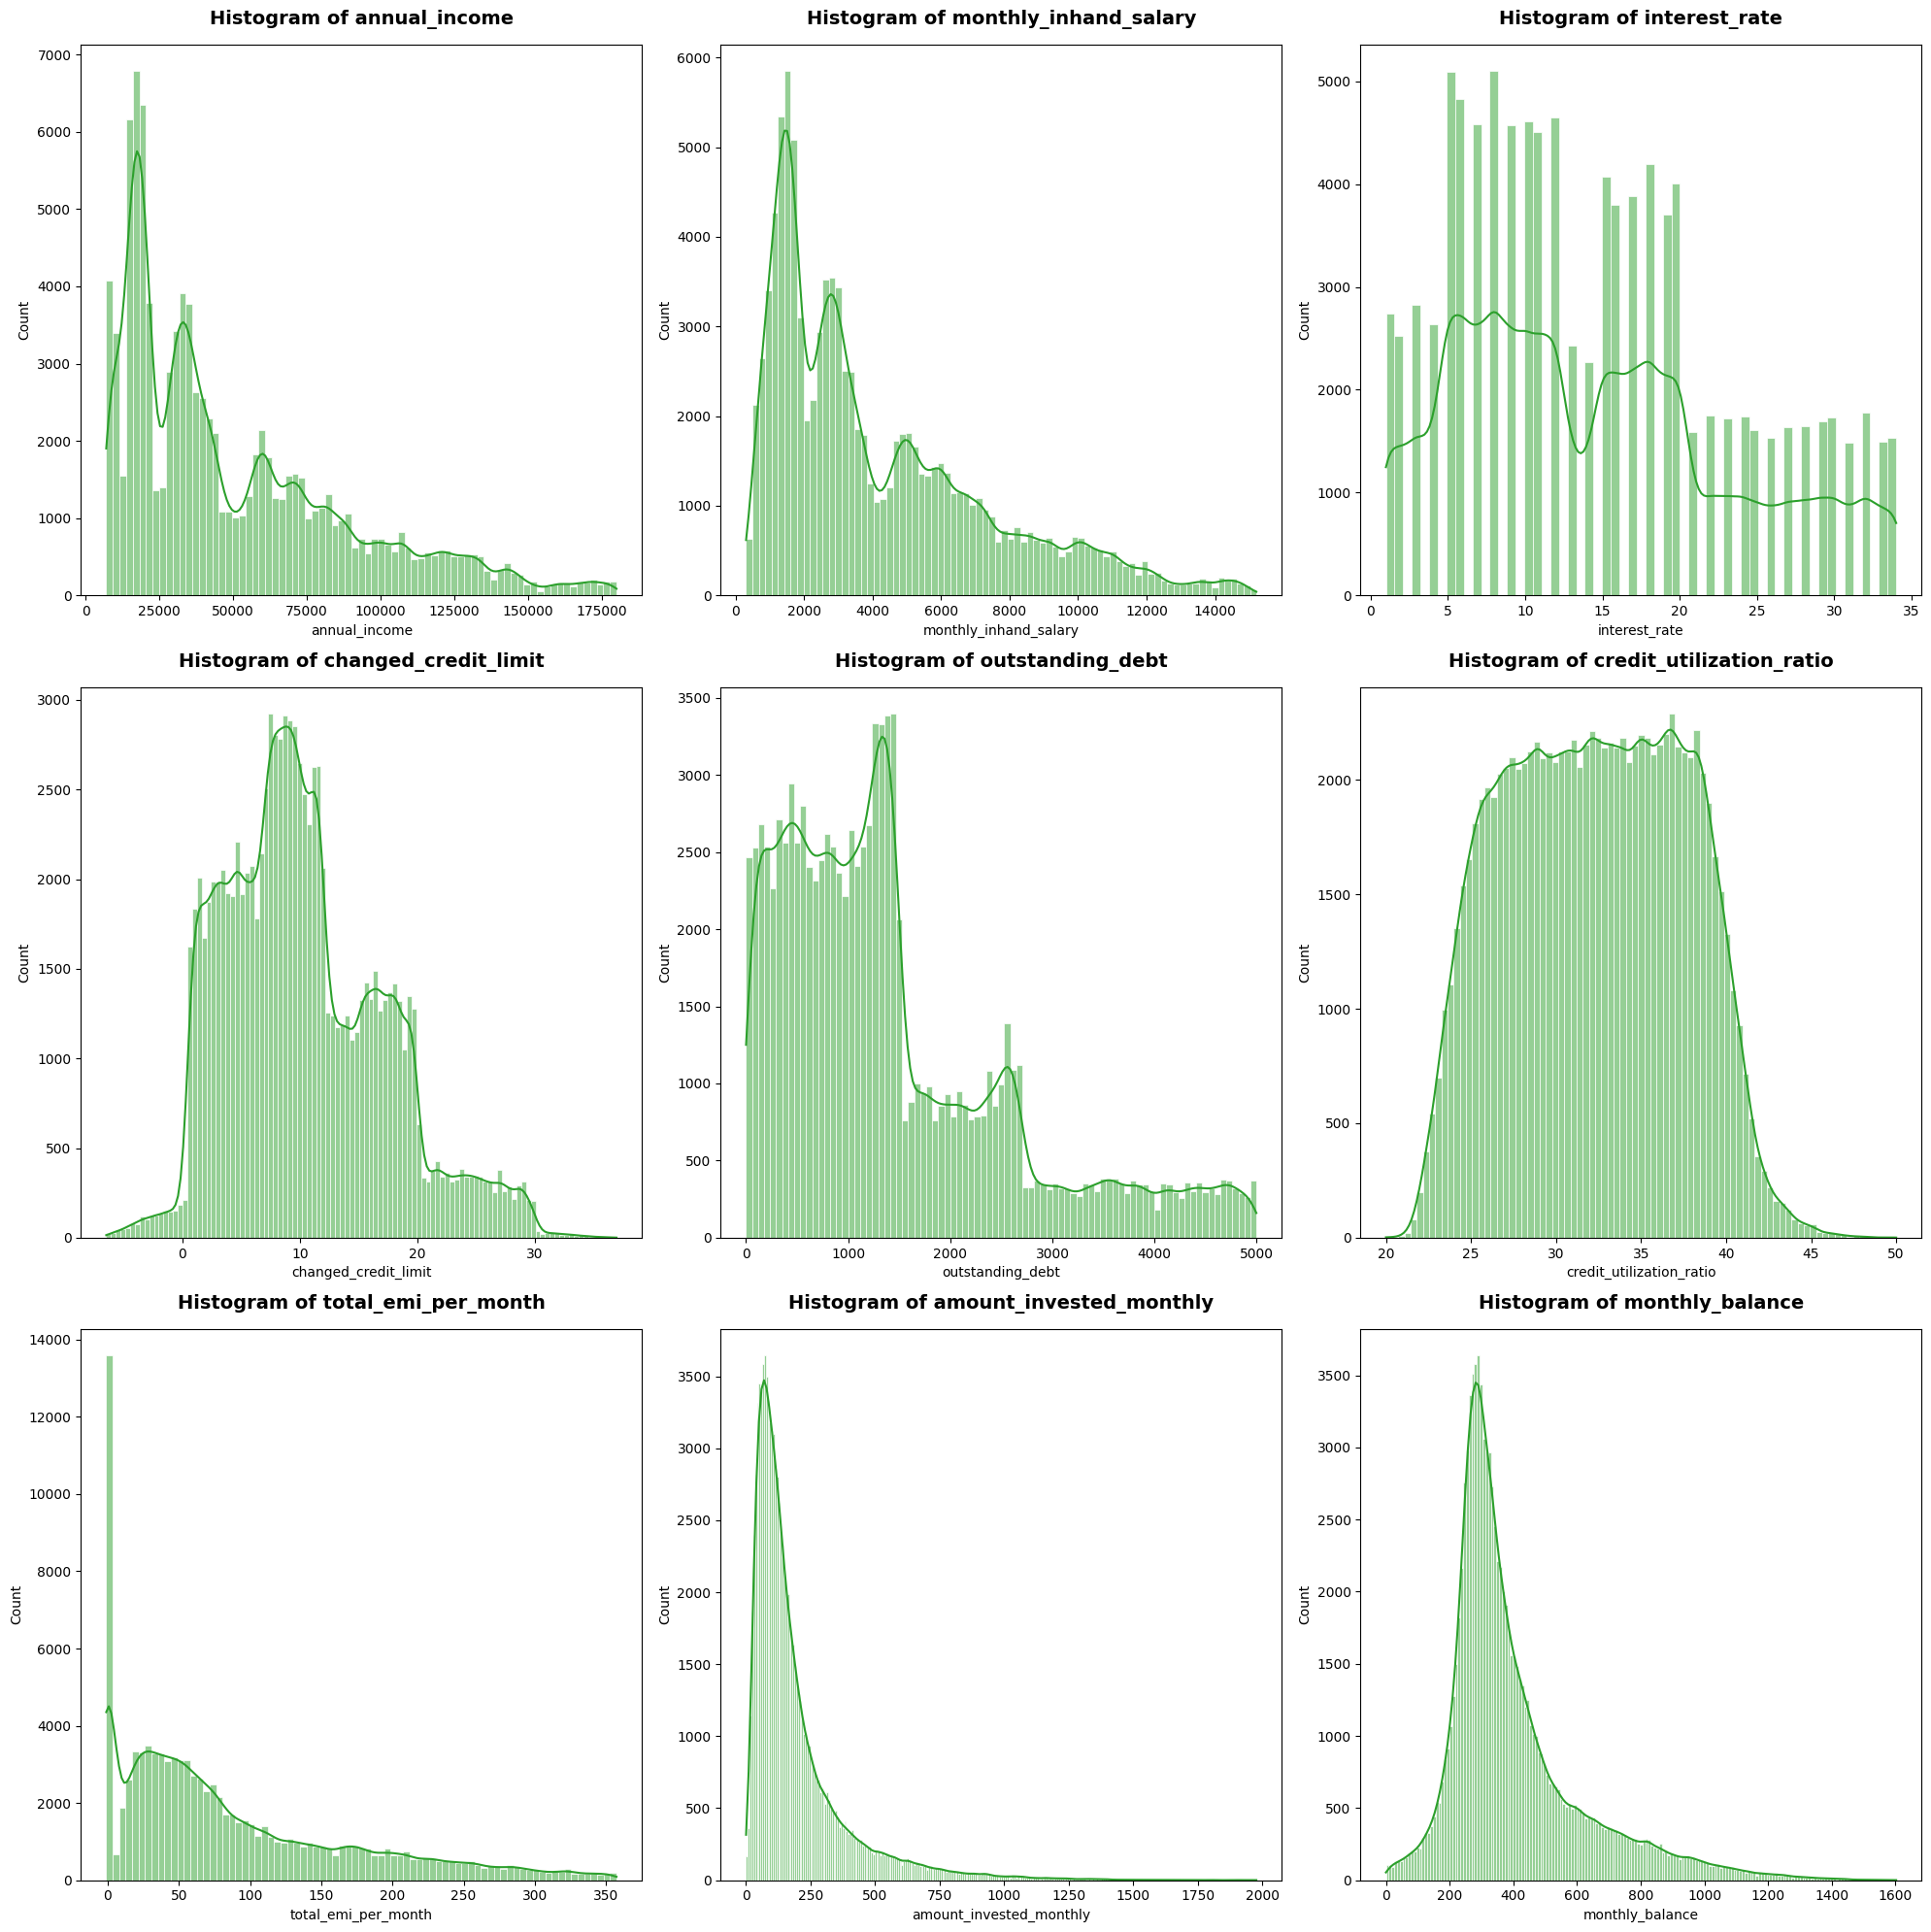

In [ ]:
# Draw histogram for 8 discrete ratio variables
dis_ratio_var = ['age', 'num_bank_accounts','num_credit_card','num_of_loan','delay_from_due_date','num_of_delayed_payment',
                    'num_credit_inquiries','credit_history_age' ]

fig, axes = plt.subplots(4,2,figsize = (20,20))
axes = axes.flatten()

for var, ax in zip(dis_ratio_var, axes):
    include_num = 'num' in var.lower()
    kde_status = False if include_num else True
    color =  'tab:blue' if include_num else 'tab:orange'
    sns.histplot(data = df, x = var, kde = kde_status, stat = 'count', discrete = True, color = color, kde_kws = {'bw_adjust': 0.7}, edgecolor = 'w', linewidth = 0.5, ax = ax)
    ax.set_title(f'Histogram of {var}', fontsize = 14, fontweight = 'bold', pad = 15)

plt.tight_layout()

# Draw histogram for 9 continuous ratio variables
con_ratio_var = ['annual_income','monthly_inhand_salary','interest_rate','changed_credit_limit','outstanding_debt',
                'credit_utilization_ratio','total_emi_per_month','amount_invested_monthly','monthly_balance']

fig, axes = plt.subplots(3,3,figsize = (20,20))
axes = axes.flatten()

for var, ax in zip(con_ratio_var, axes):
    sns.histplot(data = df, x = var, kde = True, stat = 'count', kde_kws = {'bw_adjust':0.7}, color = 'tab:green', edgecolor = 'w', linewidth = 0.5, ax = ax)
    ax.set_title(f'Histogram of {var}', fontsize = 14, fontweight = 'bold', pad = 15)

plt.tight_layout()
plt.show()

### Feature Engineering

In [ ]:
# Create a copy dataset for further trainning models
df_train = df.copy()

#### Encoding nominal variables including feature variables

In [ ]:
nominal_var = ['occupation','payment_of_min_amount','last_loan_1','last_loan_2','last_loan_3','last_loan_4','last_loan_5','last_loan_6','last_loan_7',
                'last_loan_8','last_loan_9']
df_train = pd.get_dummies(data = df, columns = nominal_var, drop_first = True, dtype = int)
display(df_train.head())

,customer_id,age,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,total_emi_per_month,amount_invested_monthly,payment_behaviour,monthly_balance,credit_score,payment_level,payment_volume,occupation_Architect,occupation_Developer,occupation_Doctor,occupation_Engineer,occupation_Entrepreneur,occupation_Journalist,occupation_Lawyer,occupation_Manager,occupation_Mechanic,occupation_Media_Manager,occupation_Musician,occupation_Scientist,occupation_Teacher,occupation_Writer,payment_of_min_amount_Yes,last_loan_1_Credit-Builder Loan,last_loan_1_Debt Consolidation Loan,last_loan_1_Home Equity Loan,last_loan_1_Mortgage Loan,last_loan_1_No Loan,last_loan_1_Not Specified,last_loan_1_Payday Loan,last_loan_1_Personal Loan,last_loan_1_Student Loan,last_loan_2_Credit-Builder Loan,last_loan_2_Debt Consolidation Loan,last_loan_2_Home Equity Loan,last_loan_2_Mortgage Loan,last_loan_2_No Loan,last_loan_2_Not Specified,last_loan_2_Payday Loan,last_loan_2_Personal Loan,last_loan_2_Student Loan,last_loan_3_Credit-Builder Loan,last_loan_3_Debt Consolidation Loan,last_loan_3_Home Equity Loan,last_loan_3_Mortgage Loan,last_loan_3_No Loan,last_loan_3_Not Specified,last_loan_3_Payday Loan,last_loan_3_Personal Loan,last_loan_3_Student Loan,last_loan_4_Credit-Builder Loan,last_loan_4_Debt Consolidation Loan,last_loan_4_Home Equity Loan,last_loan_4_Mortgage Loan,last_loan_4_No Loan,last_loan_4_Not Specified,last_loan_4_Payday Loan,last_loan_4_Personal Loan,last_loan_4_Student Loan,last_loan_5_Credit-Builder Loan,last_loan_5_Debt Consolidation Loan,last_loan_5_Home Equity Loan,last_loan_5_Mortgage Loan,last_loan_5_No Loan,last_loan_5_Not Specified,last_loan_5_Payday Loan,last_loan_5_Personal Loan,last_loan_5_Student Loan,last_loan_6_Credit-Builder Loan,last_loan_6_Debt Consolidation Loan,last_loan_6_Home Equity Loan,last_loan_6_Mortgage Loan,last_loan_6_No Loan,last_loan_6_Not Specified,last_loan_6_Payday Loan,last_loan_6_Personal Loan,last_loan_6_Student Loan,last_loan_7_Credit-Builder Loan,last_loan_7_Debt Consolidation Loan,last_loan_7_Home Equity Loan,last_loan_7_Mortgage Loan,last_loan_7_No Loan,last_loan_7_Not Specified,last_loan_7_Payday Loan,last_loan_7_Personal Loan,last_loan_7_Student Loan,last_loan_8_Credit-Builder Loan,last_loan_8_Debt Consolidation Loan,last_loan_8_Home Equity Loan,last_loan_8_Mortgage Loan,last_loan_8_No Loan,last_loan_8_Not Specified,last_loan_8_Payday Loan,last_loan_8_Personal Loan,last_loan_8_Student Loan,last_loan_9_Credit-Builder Loan,last_loan_9_Debt Consolidation Loan,last_loan_9_Home Equity Loan,last_loan_9_Mortgage Loan,last_loan_9_No Loan,last_loan_9_Not Specified,last_loan_9_Payday Loan,last_loan_9_Personal Loan,last_loan_9_Student Loan
0,CUS_0x98ed,31,22229.060,1672.421667,6,4,5.0,3,10,10,9.44,9,Standard,1396.14,33.061861,156,52.138474,44.084010,High_spent_Medium_value_payments,321.019683,Standard,High payment,Medium payment,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
1,CUS_0x36b4,43,17060.705,1685.725417,8,3,11.0,4,24,8,9.64,2,Standard,268.81,36.377621,269,51.934634,39.628311,Low_spent_Small_value_payments,327.009597,Standard,Low payment,Small payment,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
2,CUS_0x105b,24,34428.210,2575.017500,2,4,8.0,0,3,12,8.51,0,Good,180.70,39.917508,326,0.000000,84.774645,High_spent_Small_value_payments,432.727105,Good,High payment,Small payment,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0

#### Mapping ordinal variables including both feature and target variables

In [ ]:
# Mapping rules
credit_map = {'Bad': 0, 'Poor': 0, 'Standard': 1, 'Good': 2}
df_train[['credit_mix', 'credit_score']] = df_train[['credit_mix', 'credit_score']].replace(credit_map, inplace = True)

payment_level_map = {'High payment': 0, 'Low payment': 1}
df_train['payment_level'] = df_train['payment_level'].replace(payment_level_map, inplace = True)

payment_volume_map = {'Small payment': 0, 'Medium payment':1, 'Large payment': 2}
df_train['payment_volume'] = df_train['payment_volume'].replace(payment_volume_map, inplace = True)

# Check if they are mapped or not
ordinal_var = ['credit_mix', 'payment_level', 'payment_volume', 'credit_score']

for var in ordinal_var:
    unique_values = df_train[var].unique()
    print(f'The unique values of column {var} is:')
    print(unique_values)

print('Original dataset before feature engineering:')
display(df.head(5))
print('Dataset after feature engineering:')
display(df_train.head(5))


The unique values of column credit_mix is:
[1 2 0]
The unique values of column payment_level is:
[0 1]
The unique values of column payment_volume is:
[1 0 2]
The unique values of column credit_score is:
[1 2 0]
Original dataset before feature engineering:


C:\Users\voila\AppData\Local\Temp\ipykernel_20572\2554850550.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_train[['credit_mix', 'credit_score']] = df_train[['credit_mix', 'credit_score']].replace(credit_map, inplace = True)
C:\Users\voila\AppData\Local\Temp\ipykernel_20572\2554850550.py:7: ChainedAssignmentError: A value is 

,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,payment_behaviour,monthly_balance,last_loan_9,last_loan_8,last_loan_7,last_loan_6,last_loan_5,last_loan_4,last_loan_3,last_loan_2,last_loan_1,credit_score,payment_level,payment_volume
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,10,9.44,9,Standard,1396.14,33.061861,156,Yes,52.138474,44.084010,High_spent_Medium_value_payments,321.019683,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Debt Consolidation Loan,Standard,High payment,Medium payment
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,8,9.64,2,Standard,268.81,36.377621,269,Yes,51.934634,39.628311,Low_spent_Small_value_payments,327.009597,No Loan,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Auto Loan,Auto Loan,Standard,Low payment,Small payment
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,12,8.51,0,Good,180.70,39.917508,326,No,0.000000,84.774645,High_spent_Small_value_payments,432.727105,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Good,High payment,Small payment
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,17,17.51,3,Standard,569.11,39.841494,376,Yes,16.941903,41.943603,Low_spent_Medium_value_payments,346.630494,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Personal Loan,Student Loan,Home Equity Loan,Standard,Low payment,Medium payment
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,20,17.16,6,Bad,3003.45,36.058472,162,Yes,126.596814,67.970377,High_spent_Medium_value_payments,360.325808,No Loan,No Loan,No Loan,No Loan,Auto Loan,Mortgage Loan,Auto Loan,Payday Loan,Not Specified,Poor,High payment,Medium payment


Dataset after feature engineering:


,customer_id,age,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,total_emi_per_month,amount_invested_monthly,payment_behaviour,monthly_balance,credit_score,payment_level,payment_volume,occupation_Architect,occupation_Developer,occupation_Doctor,occupation_Engineer,occupation_Entrepreneur,occupation_Journalist,occupation_Lawyer,occupation_Manager,occupation_Mechanic,occupation_Media_Manager,occupation_Musician,occupation_Scientist,occupation_Teacher,occupation_Writer,payment_of_min_amount_Yes,last_loan_1_Credit-Builder Loan,last_loan_1_Debt Consolidation Loan,last_loan_1_Home Equity Loan,last_loan_1_Mortgage Loan,last_loan_1_No Loan,last_loan_1_Not Specified,last_loan_1_Payday Loan,last_loan_1_Personal Loan,last_loan_1_Student Loan,last_loan_2_Credit-Builder Loan,last_loan_2_Debt Consolidation Loan,last_loan_2_Home Equity Loan,last_loan_2_Mortgage Loan,last_loan_2_No Loan,last_loan_2_Not Specified,last_loan_2_Payday Loan,last_loan_2_Personal Loan,last_loan_2_Student Loan,last_loan_3_Credit-Builder Loan,last_loan_3_Debt Consolidation Loan,last_loan_3_Home Equity Loan,last_loan_3_Mortgage Loan,last_loan_3_No Loan,last_loan_3_Not Specified,last_loan_3_Payday Loan,last_loan_3_Personal Loan,last_loan_3_Student Loan,last_loan_4_Credit-Builder Loan,last_loan_4_Debt Consolidation Loan,last_loan_4_Home Equity Loan,last_loan_4_Mortgage Loan,last_loan_4_No Loan,last_loan_4_Not Specified,last_loan_4_Payday Loan,last_loan_4_Personal Loan,last_loan_4_Student Loan,last_loan_5_Credit-Builder Loan,last_loan_5_Debt Consolidation Loan,last_loan_5_Home Equity Loan,last_loan_5_Mortgage Loan,last_loan_5_No Loan,last_loan_5_Not Specified,last_loan_5_Payday Loan,last_loan_5_Personal Loan,last_loan_5_Student Loan,last_loan_6_Credit-Builder Loan,last_loan_6_Debt Consolidation Loan,last_loan_6_Home Equity Loan,last_loan_6_Mortgage Loan,last_loan_6_No Loan,last_loan_6_Not Specified,last_loan_6_Payday Loan,last_loan_6_Personal Loan,last_loan_6_Student Loan,last_loan_7_Credit-Builder Loan,last_loan_7_Debt Consolidation Loan,last_loan_7_Home Equity Loan,last_loan_7_Mortgage Loan,last_loan_7_No Loan,last_loan_7_Not Specified,last_loan_7_Payday Loan,last_loan_7_Personal Loan,last_loan_7_Student Loan,last_loan_8_Credit-Builder Loan,last_loan_8_Debt Consolidation Loan,last_loan_8_Home Equity Loan,last_loan_8_Mortgage Loan,last_loan_8_No Loan,last_loan_8_Not Specified,last_loan_8_Payday Loan,last_loan_8_Personal Loan,last_loan_8_Student Loan,last_loan_9_Credit-Builder Loan,last_loan_9_Debt Consolidation Loan,last_loan_9_Home Equity Loan,last_loan_9_Mortgage Loan,last_loan_9_No Loan,last_loan_9_Not Specified,last_loan_9_Payday Loan,last_loan_9_Personal Loan,last_loan_9_Student Loan
0,CUS_0x98ed,31,22229.060,1672.421667,6,4,5.0,3,10,10,9.44,9,1,1396.14,33.061861,156,52.138474,44.084010,High_spent_Medium_value_payments,321.019683,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
1,CUS_0x36b4,43,17060.705,1685.725417,8,3,11.0,4,24,8,9.64,2,1,268.81,36.377621,269,51.934634,39.628311,Low_spent_Small_value_payments,327.009597,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
2,CUS_0x105b,24,34428.210,2575.017500,2,4,8.0,0,3,12,8.51,0,2,180.70,39.917508,326,0.000000,84.774645,High_spent_Small_value_payments,432.727105,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
3,CUS_0x4c4a,21,12613.920,1155.160000,4,6,13.0,3,14,17,17.51,3,1,569